In [1]:
import cv2
img = cv2.imread("IMG_20260831_164908.jpg")
print(img.shape)

(4096, 3072, 3)


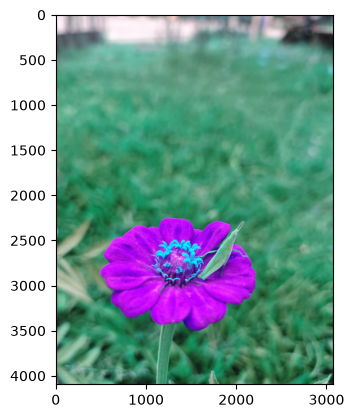

In [2]:
import matplotlib.pyplot as plt
plt.imshow(img)
plt.show()

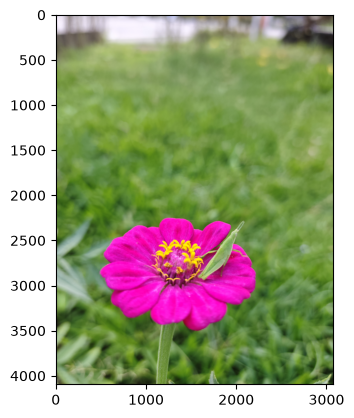

In [3]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.show()

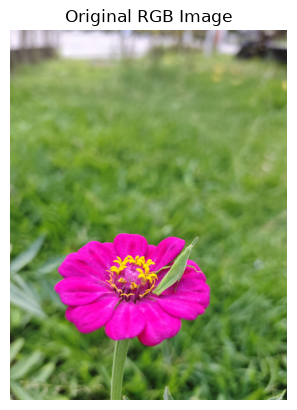

In [4]:
plt.imshow(img_rgb)
plt.title("Original RGB Image")
plt.axis("off")
plt.show()

In [5]:
means = img_rgb.reshape(-1, 3).mean(axis=0)
stds = img_rgb.reshape(-1, 3).std(axis=0)
print("Means (R,G,B):", means)
print("Stds  (R,G,B):", stds

Means (R,G,B): [129.38890012 132.96041401  89.57237609]
Stds  (R,G,B): [50.72589787 48.06723381 52.20169406]


In [9]:
import numpy as np
img_float = img_rgb.astype(np.float64)
img_normalized = (img_float - means) / stds

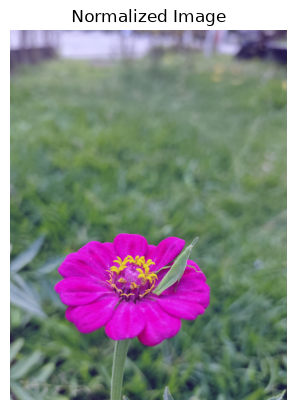

In [10]:
display_version = (img_normalized - img_normalized.min()) / (img_normalized.max() - img_normalized.min())
plt.imshow(display_version)
plt.title("Normalized Image")
plt.axis("off")
plt.show()

In [11]:
print("Before normalization - mean:", means, " std:", stds)
print("After normalization  - mean:", img_normalized.reshape(-1,3).mean(axis=0))
print("After normalization  - std :", img_normalized.reshape(-1,3).std(axis=0))

Before normalization - mean: [129.38890012 132.96041401  89.57237609]  std: [50.72589787 48.06723381 52.20169406]
After normalization  - mean: [ 8.25218490e-13 -3.24167048e-13 -7.74719831e-13]
After normalization  - std : [1. 1. 1.]


In [12]:
height, width, channels = img_rgb.shape
print("Height   :", height)
print("Width    :", width)
print("Channels :", channels)
print("Data type:", img_rgb.dtype)
print("Total pixels (H x W):", height * width)
print("Total values (H x W x C):", img_rgb.size)

Height   : 4096
Width    : 3072
Channels : 3
Data type: uint8
Total pixels (H x W): 12582912
Total values (H x W x C): 37748736


Crop shape: (1024, 768, 3)


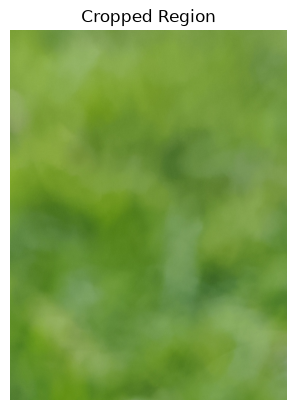

In [13]:
h, w = img_rgb.shape[:2]
y1, y2 = h // 4, h // 4 + h // 4
x1, x2 = w // 4, w // 4 + w // 4
cropped = img_rgb[y1:y2, x1:x2]

print("Crop shape:", cropped.shape)
plt.imshow(cropped)
plt.title("Cropped Region")
plt.axis("off")
plt.show()

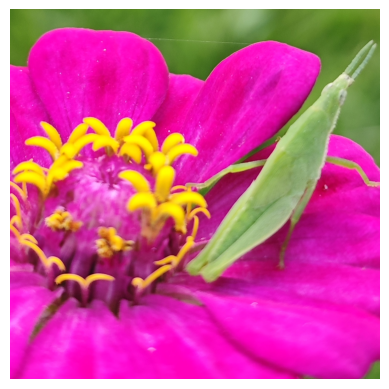

In [14]:
y1, y2 = 2200, 3200
x1, x2 = 1100, 2100
cropped = img_rgb[y1:y2, x1:x2]
plt.imshow(cropped)
plt.axis("off")
plt.show()

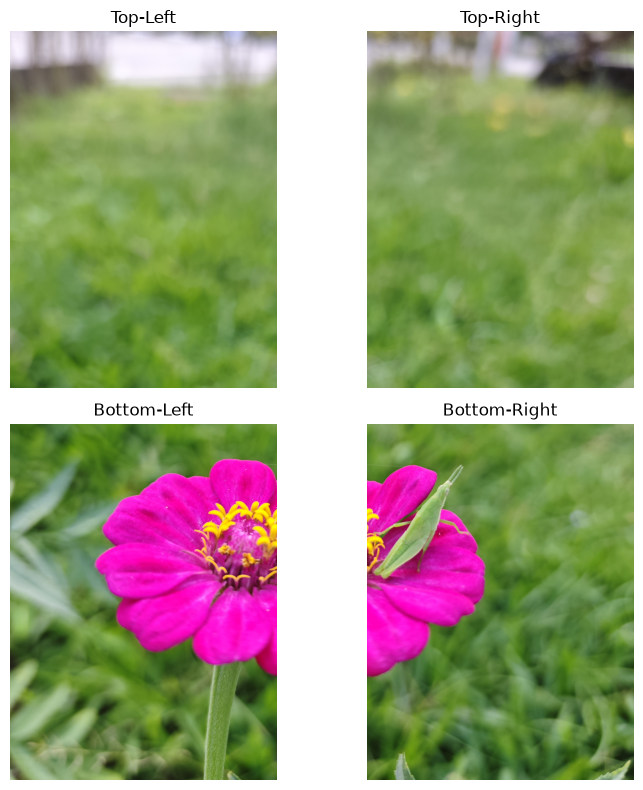

In [15]:
h, w = img_rgb.shape[:2]
mid_h, mid_w = h // 2, w // 2

top_left = img_rgb[0:mid_h, 0:mid_w]
top_right = img_rgb[0:mid_h, mid_w:w]
bottom_left = img_rgb[mid_h:h, 0:mid_w]
bottom_right = img_rgb[mid_h:h, mid_w:w]

fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes[0,0].imshow(top_left);     axes[0,0].set_title("Top-Left");     axes[0,0].axis("off")
axes[0,1].imshow(top_right);    axes[0,1].set_title("Top-Right");    axes[0,1].axis("off")
axes[1,0].imshow(bottom_left);  axes[1,0].set_title("Bottom-Left");  axes[1,0].axis("off")
axes[1,1].imshow(bottom_right); axes[1,1].set_title("Bottom-Right"); axes[1,1].axis("off")
plt.tight_layout()
plt.show()

Merged shape: (4096, 3072, 3)
Matches original exactly: True


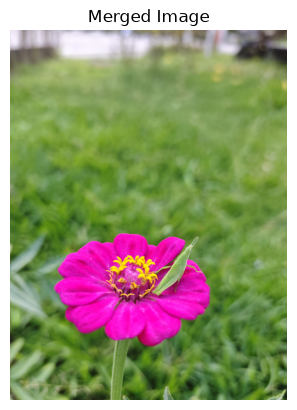

In [16]:
top_row = np.hstack((top_left, top_right))
bottom_row = np.hstack((bottom_left, bottom_right))
merged = np.vstack((top_row, bottom_row))

print("Merged shape:", merged.shape)
print("Matches original exactly:", np.array_equal(merged, img_rgb[:mid_h*2, :mid_w*2]))

plt.imshow(merged)
plt.title("Merged Image")
plt.axis("off")
plt.show()

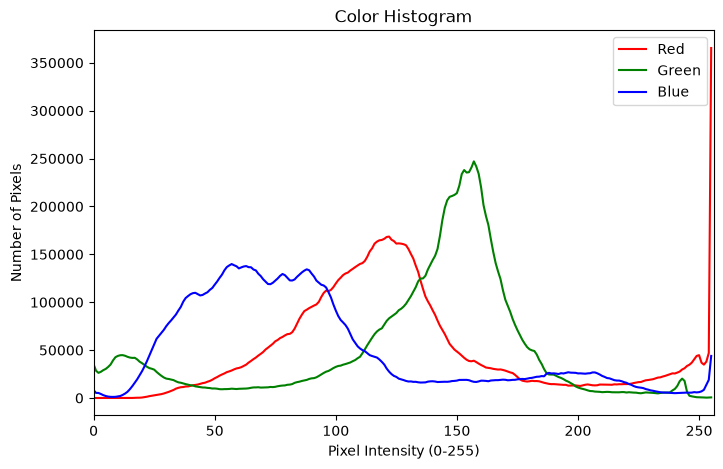

In [17]:
colors = ("r", "g", "b")
labels = ("Red", "Green", "Blue")

plt.figure(figsize=(8, 5))
for i, (c, label) in enumerate(zip(colors, labels)):
    hist = cv2.calcHist([img_rgb], [i], None, [256], [0, 256])
    plt.plot(hist, color=c, label=label)

plt.title("Color Histogram")
plt.xlabel("Pixel Intensity (0-255)")
plt.ylabel("Number of Pixels")
plt.xlim([0, 256])
plt.legend()
plt.show()

Grayscale shape: (4096, 3072)


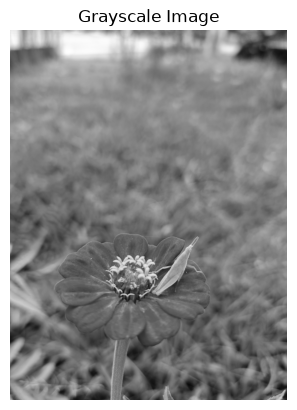

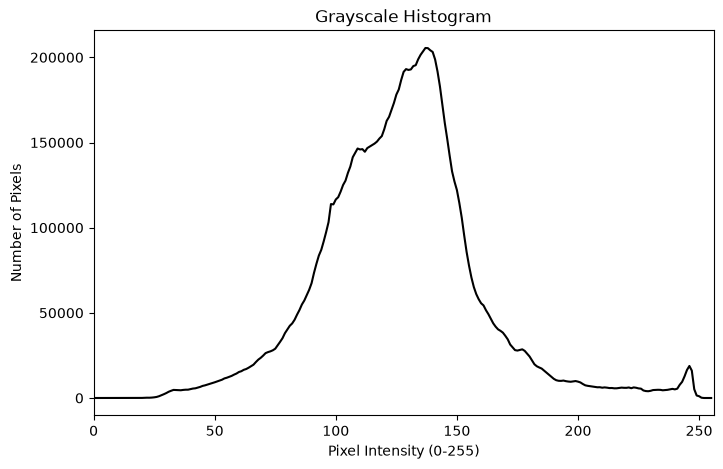

In [18]:
gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
print("Grayscale shape:", gray.shape)

plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

gray_hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
plt.figure(figsize=(8, 5))
plt.plot(gray_hist, color="black")
plt.title("Grayscale Histogram")
plt.xlabel("Pixel Intensity (0-255)")
plt.ylabel("Number of Pixels")
plt.xlim([0, 256])
plt.show()

Original shape    : (4096, 3072, 3)
Zoomed-in shape    : (8192, 6144, 3)
Zoomed-out shape   : (2048, 1536, 3)


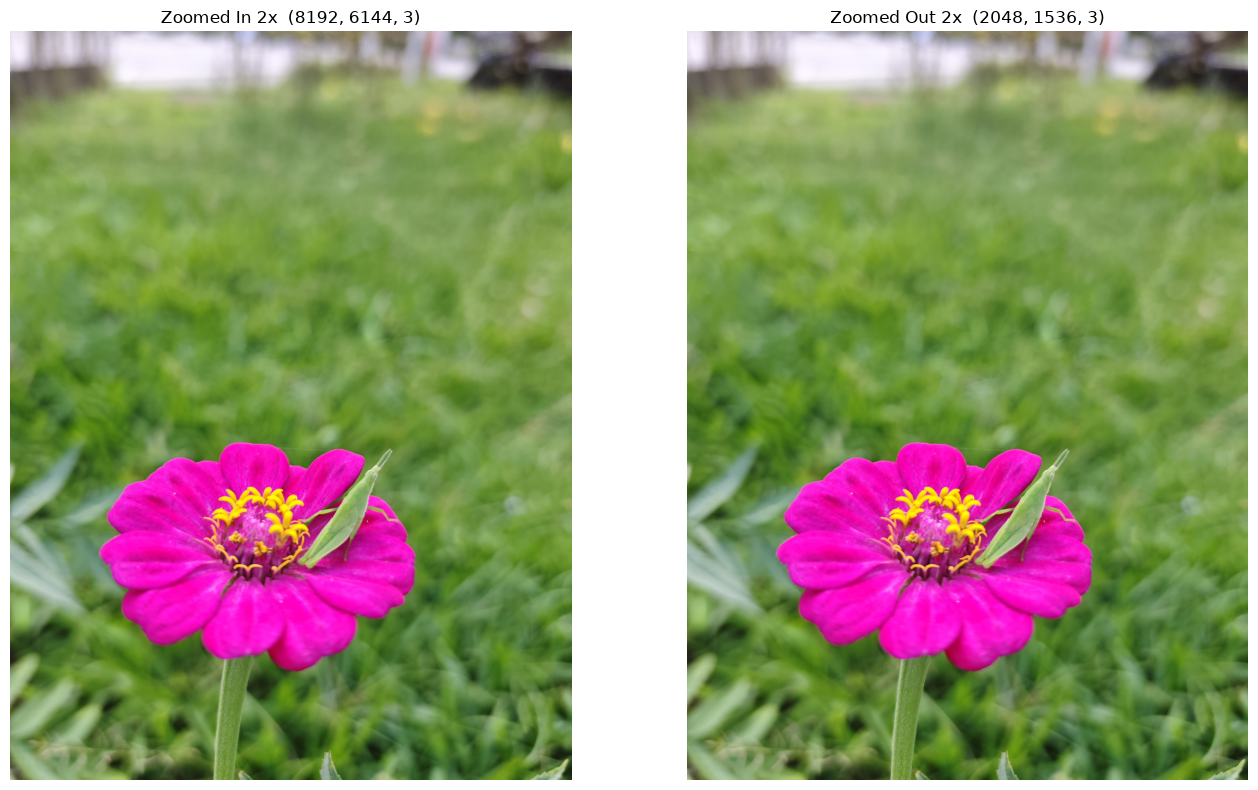

In [19]:
zoomed_in = cv2.resize(img_rgb, None, fx=2, fy=2, interpolation=cv2.INTER_LINEAR)
zoomed_out = cv2.resize(img_rgb, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_LINEAR)

print("Original shape    :", img_rgb.shape)
print("Zoomed-in shape    :", zoomed_in.shape)
print("Zoomed-out shape   :", zoomed_out.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
axes[0].imshow(zoomed_in)
axes[0].set_title(f"Zoomed In 2x  {zoomed_in.shape}")
axes[0].axis("off")
axes[1].imshow(zoomed_out)
axes[1].set_title(f"Zoomed Out 2x  {zoomed_out.shape}")
axes[1].axis("off")
plt.tight_layout()
plt.show()

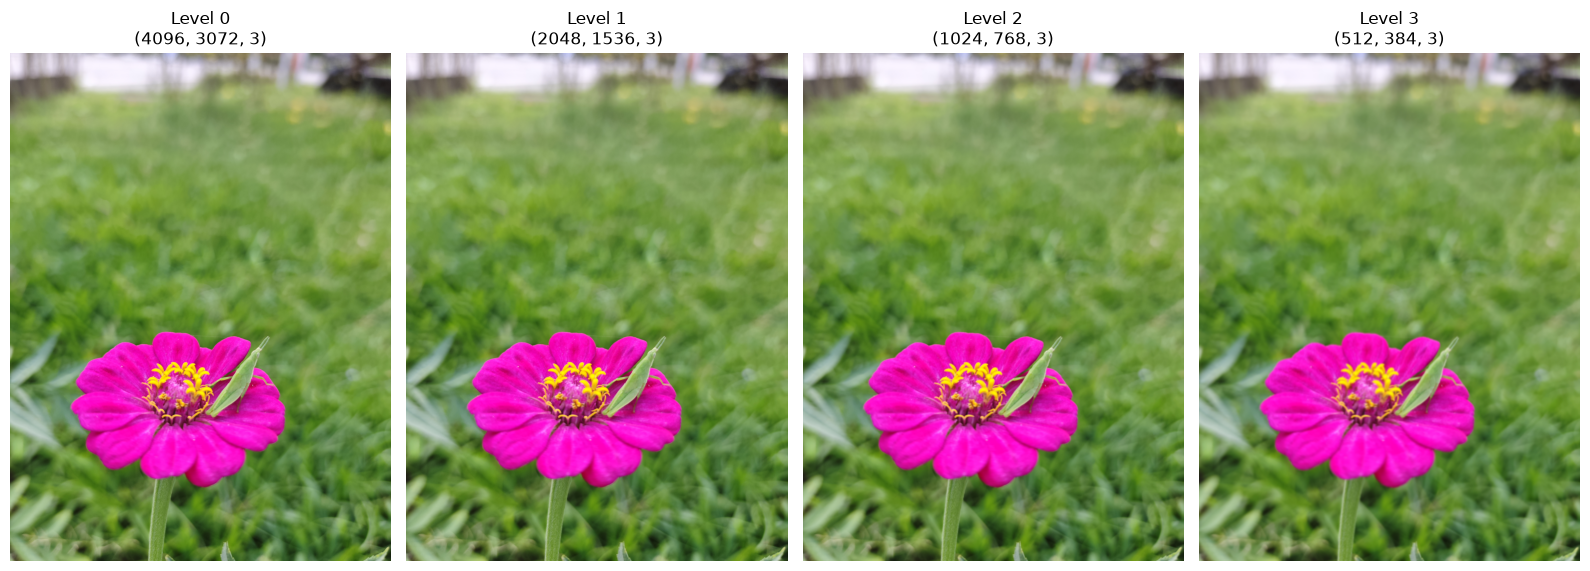

Level 0: shape = (4096, 3072, 3)
Level 1: shape = (2048, 1536, 3)
Level 2: shape = (1024, 768, 3)
Level 3: shape = (512, 384, 3)


In [20]:
pyramid = [img_rgb]
current = img_rgb
n_levels = 4

for level in range(1, n_levels):
    current = cv2.pyrDown(current)
    pyramid.append(current)

fig, axes = plt.subplots(1, n_levels, figsize=(16, 6))
for i, (ax, level_img) in enumerate(zip(axes, pyramid)):
    ax.imshow(level_img)
    ax.set_title(f"Level {i}\n{level_img.shape}")
    ax.axis("off")
plt.tight_layout()
plt.show()

for i, level_img in enumerate(pyramid):
    print(f"Level {i}: shape = {level_img.shape}")